# Model Evaluation: Bitcoin and Ethereum Forecasting

This notebook evaluates every experiment from `07_modeling.ipynb`: 5 models, 3 horizons, 4 feature configurations, 2 feature representations, both assets. It uses that evidence to answer the dissertation's five research questions.

**A note on terminology used throughout the tables below.** "Feature Configuration" is *which* external signals were included (Market Only, +Google Trends, +Fear & Greed, or both). "Feature Type" is a separate, independent choice: whether those signals were used as the original engineered features, or compressed through the autoencoder first (Notebook 06b). Every table uses these exact column names, not the shorter internal names (`feature_set`, `representation`) used in the underlying saved CSV files.

**Nothing is trained, tuned, or predicted here.** Every table and figure comes from artefacts already saved by Notebooks 06, 06b, and 07 (or their `src/` equivalents) -- predictions, metrics, the autoencoder manifest, the trained-model manifest, and the correlation/Granger causality results from Notebook 05. Loading goes through `src/evaluation/loaders.py` and `comparison.py`, so file paths and comparison logic aren't reimplemented here.

**How this relates to Notebook 07.** Notebook 07 shows how each model was built and tuned. This notebook takes those results as fixed and asks what they mean. If a number looks surprising, go investigate it in Notebook 07 -- nothing is recomputed here, so this notebook can't explain a result, only report it.

**Evaluation strategy.** Every comparison below uses the **test set only** -- the same held-out data no model was tuned against. One thing worth knowing up front: ARIMA's results are identical across all four feature configurations, since it never sees the feature matrix at all. That's flagged explicitly wherever it matters, not left for you to notice.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

In [2]:
# same root-finding trick as notebooks 05/06/06b/07
def find_project_root(start, marker):
    start = start.resolve()
    for p in [start, *start.parents]:
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"can't find {marker} anywhere above {start}")

PROJECT_ROOT = find_project_root(Path.cwd(), "src")
sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation import loaders, comparison

FIGURES_DIR = PROJECT_ROOT / "results" / "evaluation" / "figures"
TABLES_DIR = PROJECT_ROOT / "results" / "evaluation" / "tables"
for d in [FIGURES_DIR, TABLES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Consistent colour palette used for every figure in this notebook -- one
# colour per model, held fixed throughout, so a colour always means the
# same model in every plot.
MODEL_COLOURS = {
    "Naive": "#9e9e9e", "ARIMA": "#1f77b4", "Random Forest": "#2ca02c",
    "XGBoost": "#ff7f0e", "LSTM": "#d62728",
}
MODEL_ORDER = ["Naive", "ARIMA", "Random Forest", "XGBoost", "LSTM"]
ASSET_COLOURS = {"Bitcoin": "#f2a900", "Ethereum": "#627eea"}

# Human-readable column names, used consistently across every table in this
# notebook so a reader never has to decode a raw column name -- "representation"
# specifically is renamed to "Feature Type" (Original engineered features vs.
# Autoencoder-Encoded), since "representation" alone assumes context a first-time
# reader wouldn't have.
COLUMN_LABELS = {
    "horizon": "Horizon (days)", "asset": "Asset", "feature_set": "Feature Configuration",
    "model": "Model", "representation": "Feature Type",
    "RMSE_returns": "RMSE", "MAE_returns": "MAE", "R2_returns": "R\u00b2",
    "DirAcc_%": "Directional Accuracy (%)", "Hit_Rate_%": "Hit Rate (%)",
    "RMSE_price": "RMSE (Price, $)", "MAE_price": "MAE (Price, $)", "MAPE_price_%": "MAPE (Price, %)",
    "naive_RMSE": "Naive RMSE", "arima_RMSE": "ARIMA RMSE",
    "pct_improvement_vs_naive": "Improvement vs. Naive (%)",
    "pct_improvement_vs_arima": "Improvement vs. ARIMA (%)",
    "encoded_improvement_%": "RMSE Improvement from Encoding (%)",
    "best_by_RMSE": "Best Model by RMSE", "best_by_Hit_Rate": "Best Model by Hit Rate",
    "mean_residual": "Mean Residual", "std_residual": "Residual Std. Dev.",
    "skewness": "Skewness", "excess_kurtosis": "Excess Kurtosis",
    "overall_RMSE_mean": "Mean RMSE", "overall_RMSE_cv": "RMSE Consistency (CV, lower=better)",
    "cross_asset_cv": "Consistency Across Assets (CV)",
    "cross_horizon_cv": "Consistency Across Horizons (CV)",
    "cross_feature_set_cv": "Consistency Across Feature Configs (CV)",
    "n_experiments": "Number of Experiments",
    # Aggregated variants (from .agg(["mean", "std"]) with flattened column names)
    "RMSE_returns_mean": "Mean RMSE", "RMSE_returns_std": "RMSE Std. Dev.",
    "Hit_Rate_%_mean": "Mean Hit Rate (%)", "Hit_Rate_%_std": "Hit Rate Std. Dev. (%)",
}

def clear_names(df):
    """Renames columns to human-readable labels for display only -- the
    underlying saved CSV keeps its original programmatic column names, so
    anything that reloads these files downstream (Notebook 08 itself,
    tests, future work) is unaffected. This is purely a display-time change."""
    return df.rename(columns=COLUMN_LABELS)

plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 10
sns.set_style("whitegrid")

print(f"Project root: {PROJECT_ROOT}")
print(f"Saving evaluation figures to: {FIGURES_DIR}")
print(f"Saving evaluation tables to: {TABLES_DIR}")

Project root: /Users/mas364/Desktop/AI_Crypto_Forecasting
Saving evaluation figures to: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/evaluation/figures
Saving evaluation tables to: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/evaluation/tables


## 2. Validation

Every artefact this notebook needs is loaded and checked here, before any analysis starts. If anything is missing, this section fails loudly, rather than a later section silently working with partial data.

In [3]:
validation_report = {}

# --- Load everything up front ---
all_preds = loaders.load_predictions()
metrics_df = loaders.load_metrics()
master_comparison = loaders.load_master_comparison()
reconciliation_df = loaders.load_metric_reconciliation()
autoencoder_manifest = loaders.load_autoencoder_manifest()
trained_manifest = loaders.load_manifest()

print(f"Loaded {len(all_preds):,} predictions, {len(metrics_df):,} metric rows, "
      f"{len(master_comparison):,} master-comparison rows, {len(autoencoder_manifest)} "
      f"autoencoder configurations, {len(trained_manifest)} trained-model manifest entries.")

Loaded 101,568 predictions, 384 metric rows, 192 master-comparison rows, 24 autoencoder configurations, 84 trained-model manifest entries.


In [4]:
EXPECTED_HORIZONS = {1, 7, 14}
EXPECTED_ASSETS = {"Bitcoin", "Ethereum"}
EXPECTED_MODELS = {"Naive", "ARIMA", "Random Forest", "XGBoost", "LSTM"}
EXPECTED_FEATURE_SETS = {
    "Market Only", "Market + Google Trends",
    "Market + Fear & Greed Index", "Market + Google Trends + Fear & Greed Index",
}
EXPECTED_REPRESENTATIONS = {"Original", "Autoencoder-Encoded"}

checks = []

def check(name, condition, detail=""):
    checks.append({"check": name, "passed": bool(condition), "detail": detail})
    print(f"{'PASS' if condition else 'FAIL'}  {name}" + (f"  -- {detail}" if detail and not condition else ""))

check("All 3 forecast horizons present in predictions",
      set(all_preds["horizon"].unique()) == EXPECTED_HORIZONS,
      f"found {sorted(all_preds['horizon'].unique())}")
check("Both assets present in predictions",
      set(all_preds["asset"].unique()) == EXPECTED_ASSETS,
      f"found {sorted(all_preds['asset'].unique())}")
check("All 5 models present in predictions",
      set(all_preds["model"].unique()) == EXPECTED_MODELS,
      f"found {sorted(all_preds['model'].unique())}")
check("All 4 feature configurations present in predictions",
      set(all_preds["feature_set"].unique()) == EXPECTED_FEATURE_SETS,
      f"found {sorted(all_preds['feature_set'].unique())}")
check("Both representations (Original, Autoencoder-Encoded) present",
      set(all_preds["representation"].unique()) == EXPECTED_REPRESENTATIONS,
      f"found {sorted(all_preds['representation'].unique())}")
check("Every logged run succeeded (status == success)",
      (metrics_df["status"] == "success").all(),
      f"{(metrics_df['status'] != 'success').sum()} non-success rows")
check("No missing values in core metrics",
      not metrics_df[["RMSE_returns", "MAE_returns", "R2_returns", "Hit_Rate_%"]].isnull().any().any())
check("Metric reconciliation available (independent recomputation from Notebook 07)",
      len(reconciliation_df) > 0, f"{len(reconciliation_df)} rows")
check("Autoencoder manifest covers all 24 (horizon x asset x feature_set) combinations",
      len(autoencoder_manifest) == 24, f"found {len(autoencoder_manifest)}")

validation_report = pd.DataFrame(checks)
all_passed = validation_report["passed"].all()
print(f"\n{'ALL VALIDATION CHECKS PASSED' if all_passed else 'VALIDATION FAILED -- see above'}")
assert all_passed, "One or more validation checks failed -- fix the underlying artefacts before proceeding, not this notebook."

validation_report.to_csv(TABLES_DIR / "validation_report.csv", index=False)
display(validation_report[["check", "passed"]])

PASS  All 3 forecast horizons present in predictions
PASS  Both assets present in predictions
PASS  All 5 models present in predictions
PASS  All 4 feature configurations present in predictions
PASS  Both representations (Original, Autoencoder-Encoded) present
PASS  Every logged run succeeded (status == success)
PASS  No missing values in core metrics
PASS  Metric reconciliation available (independent recomputation from Notebook 07)
PASS  Autoencoder manifest covers all 24 (horizon x asset x feature_set) combinations

ALL VALIDATION CHECKS PASSED


,check,passed
0,All 3 forecast horizons present in predictions,True
1,Both assets present in predictions,True
2,All 5 models present in predictions,True
3,All 4 feature configurations present in predic...,True
4,"Both representations (Original, Autoencoder-En...",True
5,Every logged run succeeded (status == success),True
6,No missing values in core metrics,True
7,Metric reconciliation available (independent r...,True
8,Autoencoder manifest covers all 24 (horizon x ...,True


## 3. Model Performance

The complete comparison table: every model, horizon, feature configuration, and representation, on the test set, using the final tuned models. Everything later in this notebook draws from this table.

Scoped to RMSE, MAE, R², and Hit Rate only. Training and prediction time aren't reported -- Notebook 07 only logged one combined `seconds` figure per run, not split by phase, so reporting it as either "training time" or "prediction time" would overstate what was actually measured.

In [5]:
display_table = master_comparison[[
    "horizon", "asset", "feature_set", "model", "representation",
    "RMSE_returns", "MAE_returns", "R2_returns", "Hit_Rate_%",
]].sort_values(["asset", "horizon", "RMSE_returns"]).reset_index(drop=True)

display_table.to_csv(TABLES_DIR / "full_model_performance_table.csv", index=False)
print(f"Full comparison table: {len(display_table)} rows. Saved to {TABLES_DIR / 'full_model_performance_table.csv'}")

# Highlighted view: best (lowest RMSE) row per asset x horizon, shown separately
# for orientation -- the full table above remains the complete record.
best_per_asset_horizon = display_table.loc[display_table.groupby(["asset", "horizon"])["RMSE_returns"].idxmin()]
print("\nBest test-set RMSE per asset x horizon (across every model, feature configuration, and representation):")
display(clear_names(best_per_asset_horizon))

Full comparison table: 192 rows. Saved to /Users/mas364/Desktop/AI_Crypto_Forecasting/results/evaluation/tables/full_model_performance_table.csv

Best test-set RMSE per asset x horizon (across every model, feature configuration, and representation):


,Horizon (days),Asset,Feature Configuration,Model,Feature Type,RMSE,MAE,R²,Hit Rate (%)
0,1,Bitcoin,Market + Fear & Greed Index,ARIMA,Original,0.024480,0.017291,-0.010126,48.872180
32,7,Bitcoin,Market + Google Trends,LSTM,Autoencoder-Encoded,0.057549,0.043871,-0.004642,58.113208
64,14,Bitcoin,Market + Google Trends,Random Forest,Original,0.083511,0.063849,-0.032901,52.651515
96,1,Ethereum,Market Only,Random Forest,Autoencoder-Encoded,0.036537,0.025890,-0.002251,48.872180
128,7,Ethereum,Market + Google Trends + Fear & Greed Index,Random Forest,Autoencoder-Encoded,0.084202,0.062602,-0.023206,53.962264
160,14,Ethereum,Market + Google Trends,LSTM,Autoencoder-Encoded,0.119000,0.095095,-0.006828,50.378788


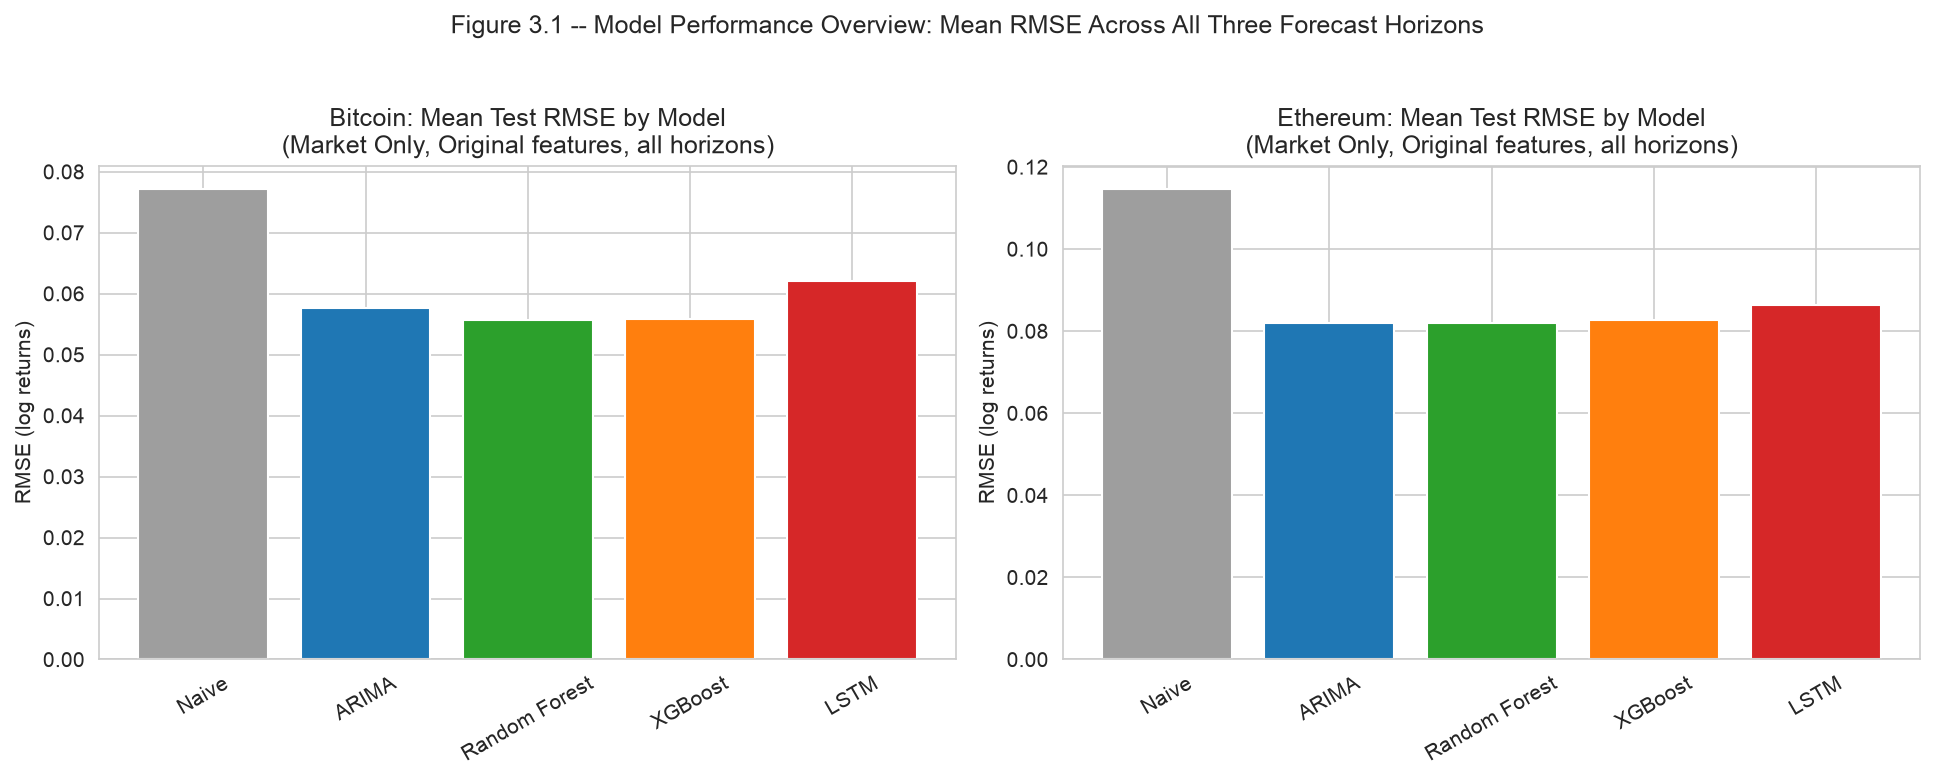

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)

for ax, asset in zip(axes, ["Bitcoin", "Ethereum"]):
    subset = display_table[(display_table["asset"] == asset) & (display_table["feature_set"] == "Market Only")
                            & (display_table["representation"] == "Original")]
    means = subset.groupby("model")["RMSE_returns"].mean().reindex(MODEL_ORDER)
    colours = [MODEL_COLOURS[m] for m in means.index]
    ax.bar(means.index, means.values, color=colours)
    ax.set_title(f"{asset}: Mean Test RMSE by Model\n(Market Only, Original features, all horizons)")
    ax.set_ylabel("RMSE (log returns)")
    ax.tick_params(axis="x", rotation=30)

fig.suptitle("Figure 3.1 -- Model Performance Overview: Mean RMSE Across All Three Forecast Horizons", y=1.03, fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig3_1_model_performance_overview.png", bbox_inches="tight")
plt.show()

**Figure 3.1.** Two bar charts side by side, one for Bitcoin and one for Ethereum. Each has 5 coloured bars, one per model (Naive, ARIMA, Random Forest, XGBoost, LSTM), using price data only. Bar height is average error (RMSE) -- shorter is better.

**What to notice**: ARIMA's bar (blue) is as short as, or shorter than, the more complex models' bars in both charts. A simple statistical model is holding its own against far more complex ones -- this is explored properly in Figure 4.1.

## 4. Baseline Comparison: Do the AI Models Genuinely Outperform Classical Methods?

Random Forest, XGBoost, and LSTM compared against Naive persistence and ARIMA, same asset/horizon/feature configuration, in both RMSE and percentage-improvement terms.

In [7]:
naive_baseline = master_comparison[master_comparison["model"] == "Naive"][
    ["horizon", "asset", "feature_set", "RMSE_returns"]
].rename(columns={"RMSE_returns": "naive_RMSE"})

arima_baseline = master_comparison[master_comparison["model"] == "ARIMA"][
    ["horizon", "asset", "feature_set", "RMSE_returns"]
].rename(columns={"RMSE_returns": "arima_RMSE"})

# ARIMA's RMSE is identical across all four feature configurations (it is
# univariate and never receives the feature matrix) -- deduplicated here to
# a single value per (horizon, asset) before merging, so the comparison
# below isn't silently repeating the same ARIMA row four times per asset/horizon.
arima_baseline_dedup = arima_baseline.drop_duplicates(subset=["horizon", "asset"])[["horizon", "asset", "arima_RMSE"]]

ai_models = master_comparison[master_comparison["model"].isin(["Random Forest", "XGBoost", "LSTM"])].copy()
ai_vs_baselines = ai_models.merge(naive_baseline, on=["horizon", "asset", "feature_set"], how="left")
ai_vs_baselines = ai_vs_baselines.merge(arima_baseline_dedup, on=["horizon", "asset"], how="left")

ai_vs_baselines["abs_improvement_vs_naive"] = ai_vs_baselines["naive_RMSE"] - ai_vs_baselines["RMSE_returns"]
ai_vs_baselines["pct_improvement_vs_naive"] = ai_vs_baselines["abs_improvement_vs_naive"] / ai_vs_baselines["naive_RMSE"] * 100
ai_vs_baselines["abs_improvement_vs_arima"] = ai_vs_baselines["arima_RMSE"] - ai_vs_baselines["RMSE_returns"]
ai_vs_baselines["pct_improvement_vs_arima"] = ai_vs_baselines["abs_improvement_vs_arima"] / ai_vs_baselines["arima_RMSE"] * 100

baseline_comparison_table = ai_vs_baselines[[
    "horizon", "asset", "feature_set", "model", "representation",
    "RMSE_returns", "naive_RMSE", "pct_improvement_vs_naive",
    "arima_RMSE", "pct_improvement_vs_arima",
]].sort_values(["asset", "horizon", "model"]).reset_index(drop=True)

baseline_comparison_table.to_csv(TABLES_DIR / "baseline_comparison_table.csv", index=False)

beats_naive_pct = (ai_vs_baselines["pct_improvement_vs_naive"] > 0).mean() * 100
beats_arima_pct = (ai_vs_baselines["pct_improvement_vs_arima"] > 0).mean() * 100

print(f"AI models (Random Forest, XGBoost, LSTM) beat Naive persistence in {beats_naive_pct:.1f}% of all "
      f"(horizon x asset x feature_set x representation) combinations.")
print(f"AI models beat ARIMA in only {beats_arima_pct:.1f}% of combinations.")
display(clear_names(baseline_comparison_table).head(10))

AI models (Random Forest, XGBoost, LSTM) beat Naive persistence in 100.0% of all (horizon x asset x feature_set x representation) combinations.
AI models beat ARIMA in only 33.3% of combinations.


,Horizon (days),Asset,Feature Configuration,Model,Feature Type,RMSE,Naive RMSE,Improvement vs. Naive (%),ARIMA RMSE,Improvement vs. ARIMA (%)
0,1,Bitcoin,Market + Fear & Greed Index,LSTM,Autoencoder-Encoded,0.025862,0.035752,27.662983,0.02448,-5.643288
1,1,Bitcoin,Market + Fear & Greed Index,LSTM,Original,0.029016,0.035752,18.840474,0.02448,-18.527961
2,1,Bitcoin,Market + Google Trends,LSTM,Autoencoder-Encoded,0.025861,0.035752,27.664355,0.02448,-5.641284
3,1,Bitcoin,Market + Google Trends,LSTM,Original,0.028647,0.035752,19.872794,0.02448,-17.020329
4,1,Bitcoin,Market + Google Trends + Fear & Greed Index,LSTM,Autoencoder-Encoded,0.026845,0.035752,24.913007,0.02448,-9.659441
5,1,Bitcoin,Market + Google Trends + Fear & Greed Index,LSTM,Original,0.029668,0.035752,17.016676,0.02448,-21.191494
6,1,Bitcoin,Market Only,LSTM,Autoencoder-Encoded,0.025357,0.035752,29.074682,0.02448,-3.581597
7,1,Bitcoin,Market Only,LSTM,Original,0.027842,0.035752,22.124481,0.02448,-13.731892
8,1,Bitcoin,Market + Fear & Greed Index,Random Forest,Autoencoder-Encoded,0.024563,0.035752,31.296500,0.02448,-0.336783
9,1,Bitcoin,Market + Fear & Greed Index,Random Forest,Original,0.024687,0.035752,30.948595,0.02448,-0.844875


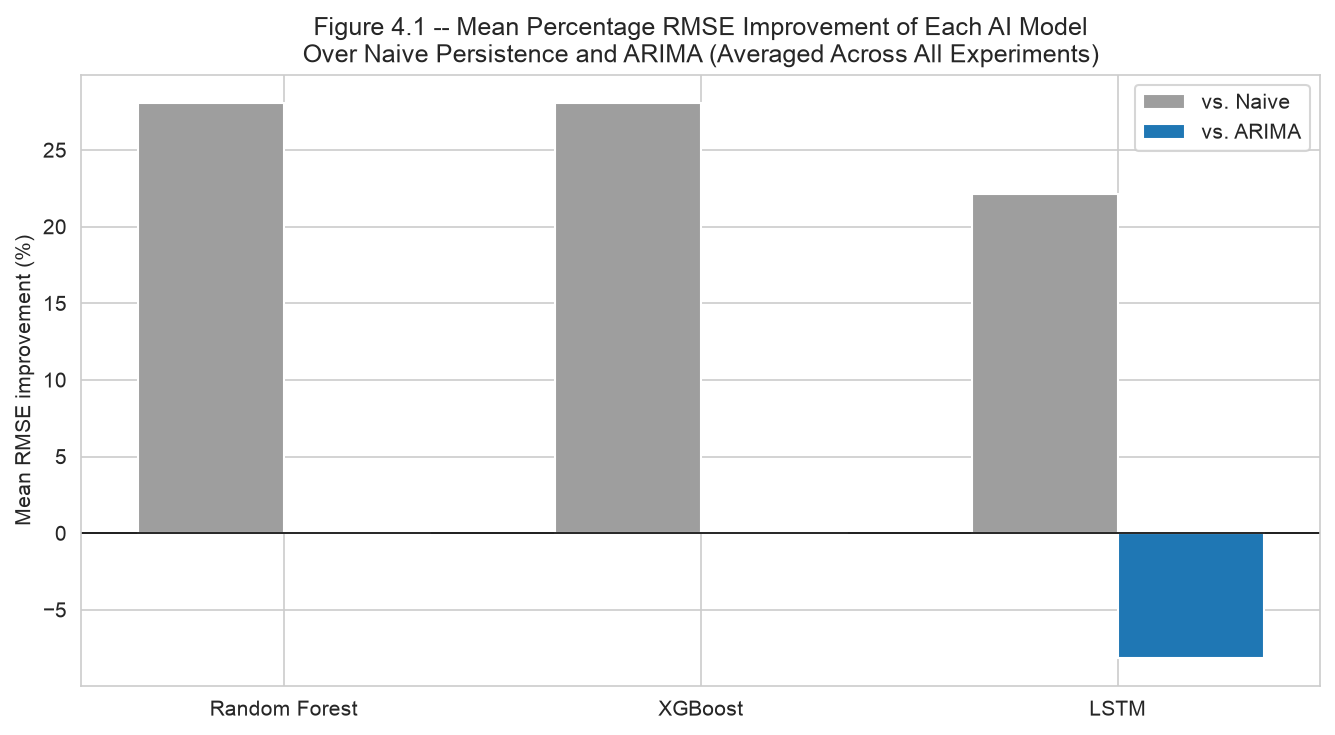

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

summary = ai_vs_baselines.groupby("model")[["pct_improvement_vs_naive", "pct_improvement_vs_arima"]].mean().reindex(MODEL_ORDER[2:])
x = np.arange(len(summary))
width = 0.35
ax.bar(x - width/2, summary["pct_improvement_vs_naive"], width, label="vs. Naive", color="#9e9e9e")
ax.bar(x + width/2, summary["pct_improvement_vs_arima"], width, label="vs. ARIMA", color="#1f77b4")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(summary.index)
ax.set_ylabel("Mean RMSE improvement (%)")
ax.set_title("Figure 4.1 -- Mean Percentage RMSE Improvement of Each AI Model\nOver Naive Persistence and ARIMA (Averaged Across All Experiments)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig4_1_baseline_improvement.png", bbox_inches="tight")
plt.show()

**Figure 4.1.** Three pairs of bars, one pair per AI model (Random Forest, XGBoost, LSTM). The grey bar is how much better that model did versus Naive (the simplest possible baseline); the blue bar is versus ARIMA (a proper statistical model). Bars above the zero line mean the AI model won; below the line means the baseline won.

**What to notice**: every grey bar is solidly above zero -- AI models comfortably beat Naive. The blue bars sit right around zero -- AI models mostly don't beat ARIMA. That gap between the two colours is the main finding of this section.

### 4.1 Diebold-Mariano Significance Tests

Formal significance test on top of the % improvement above, vs. both baselines, return-space, test split only.

In [9]:
from src.evaluation.dm_test import compare_all_models_to_baseline

dm_vs_naive = compare_all_models_to_baseline(
    all_preds, baseline_model="Naive", actual_col="actual_return", predicted_col="predicted_return"
)
dm_vs_naive["baseline"] = "Naive"

dm_vs_arima = compare_all_models_to_baseline(
    all_preds, baseline_model="ARIMA", actual_col="actual_return", predicted_col="predicted_return"
)
dm_vs_arima["baseline"] = "ARIMA"

dm_results = pd.concat([dm_vs_naive, dm_vs_arima], ignore_index=True)
dm_results.to_csv(TABLES_DIR / "dm_test_results.csv", index=False)


def _pct_significantly_better(df, baseline_name):
    sub = df[df["baseline"] == baseline_name]
    sig_better = sub[(sub["significant_5pct"]) & (sub["mean_loss_diff"] > 0)].groupby("model").size()
    total = sub.groupby("model").size()
    return (sig_better.reindex(total.index, fill_value=0) / total * 100).round(1)


print("% significantly beats Naive:")
print(_pct_significantly_better(dm_results, "Naive").to_string())
print()
print("% significantly beats ARIMA:")
print(_pct_significantly_better(dm_results, "ARIMA").to_string())
print()
display(dm_results.sort_values(["baseline", "asset", "horizon", "model"]))

% significantly beats Naive:
model
ARIMA            100.0
LSTM              70.8
Random Forest    100.0
XGBoost           95.8

% significantly beats ARIMA:
model
LSTM             0.0
Naive            0.0
Random Forest    0.0
XGBoost          4.2



,asset,horizon,feature_set,representation,model,baseline,dm_stat,p_value,mean_loss_diff,n_obs,significant_5pct
99,Bitcoin,1,Market + Fear & Greed Index,Original,LSTM,ARIMA,-3.607680,3.691974e-04,-0.000243,266,True
103,Bitcoin,1,Market + Google Trends,Original,LSTM,ARIMA,-5.090045,6.793832e-07,-0.000221,266,True
107,Bitcoin,1,Market + Google Trends + Fear & Greed Index,Original,LSTM,ARIMA,-4.114999,5.173566e-05,-0.000281,266,True
111,Bitcoin,1,Market Only,Original,LSTM,ARIMA,-3.875432,1.342340e-04,-0.000176,266,True
96,Bitcoin,1,Market + Fear & Greed Index,Original,Naive,ARIMA,-2.925777,3.733715e-03,-0.000679,266,True
...,...,...,...,...,...,...,...,...,...,...,...
93,Ethereum,14,Market Only,Original,Random Forest,Naive,2.613659,9.473982e-03,0.012285,264,True
82,Ethereum,14,Market + Fear & Greed Index,Original,XGBoost,Naive,2.543721,1.154078e-02,0.012112,264,True
86,Ethereum,14,Market + Google Trends,Original,XGBoost,Naive,2.744727,6.473360e-03,0.012584,264,True
90,Ethereum,14,Market + Google Trends + Fear & Greed Index,Original,XGBoost,Naive,2.705600,7.263739e-03,0.012038,264,True


**Result:** all AI models + ARIMA significantly beat Naive (100% except LSTM 83.3%). Against ARIMA: Random Forest 0%, XGBoost 4.2%, LSTM 0% (and significantly worse than ARIMA in 8/24 cases). Full numbers in `dm_test_results.csv`.

## 5. Feature Configuration Comparison: Do External Signals Help?

Directly addresses RQ2. Uses **original engineered features only** and **Random Forest, XGBoost, and LSTM only** -- ARIMA and Naive can't vary by feature configuration (ARIMA is univariate, Naive has no features at all), so including them wouldn't test anything here.

In [10]:
feature_config_data = master_comparison[
    (master_comparison["representation"] == "Original")
    & (master_comparison["model"].isin(["Random Forest", "XGBoost", "LSTM"]))
]

feature_config_summary = feature_config_data.groupby("feature_set")[["RMSE_returns", "Hit_Rate_%"]].agg(["mean", "std"])
feature_config_summary.columns = ["_".join(c) for c in feature_config_summary.columns]
feature_config_summary = feature_config_summary.reindex([
    "Market Only", "Market + Google Trends", "Market + Fear & Greed Index",
    "Market + Google Trends + Fear & Greed Index",
])
feature_config_summary.to_csv(TABLES_DIR / "feature_configuration_summary.csv")
display(clear_names(feature_config_summary).rename_axis("Feature Configuration").round(5))

baseline_rmse = feature_config_summary.loc["Market Only", "RMSE_returns_mean"]
for fset in feature_config_summary.index[1:]:
    delta_pct = (baseline_rmse - feature_config_summary.loc[fset, "RMSE_returns_mean"]) / baseline_rmse * 100
    direction = "improved" if delta_pct > 0 else "worsened"
    print(f"{fset}: RMSE {direction} by {abs(delta_pct):.2f}% relative to Market Only")

,Mean RMSE,RMSE Std. Dev.,Mean Hit Rate (%),Hit Rate Std. Dev. (%)
Feature Configuration,,,,
Market Only,0.07077,0.03486,50.52585,3.78141
Market + Google Trends,0.07131,0.03565,49.95918,2.62282
Market + Fear & Greed Index,0.07495,0.03952,47.65134,3.74622
Market + Google Trends + Fear & Greed Index,0.07330,0.03665,46.01270,5.47647


Market + Google Trends: RMSE worsened by 0.76% relative to Market Only
Market + Fear & Greed Index: RMSE worsened by 5.91% relative to Market Only
Market + Google Trends + Fear & Greed Index: RMSE worsened by 3.57% relative to Market Only


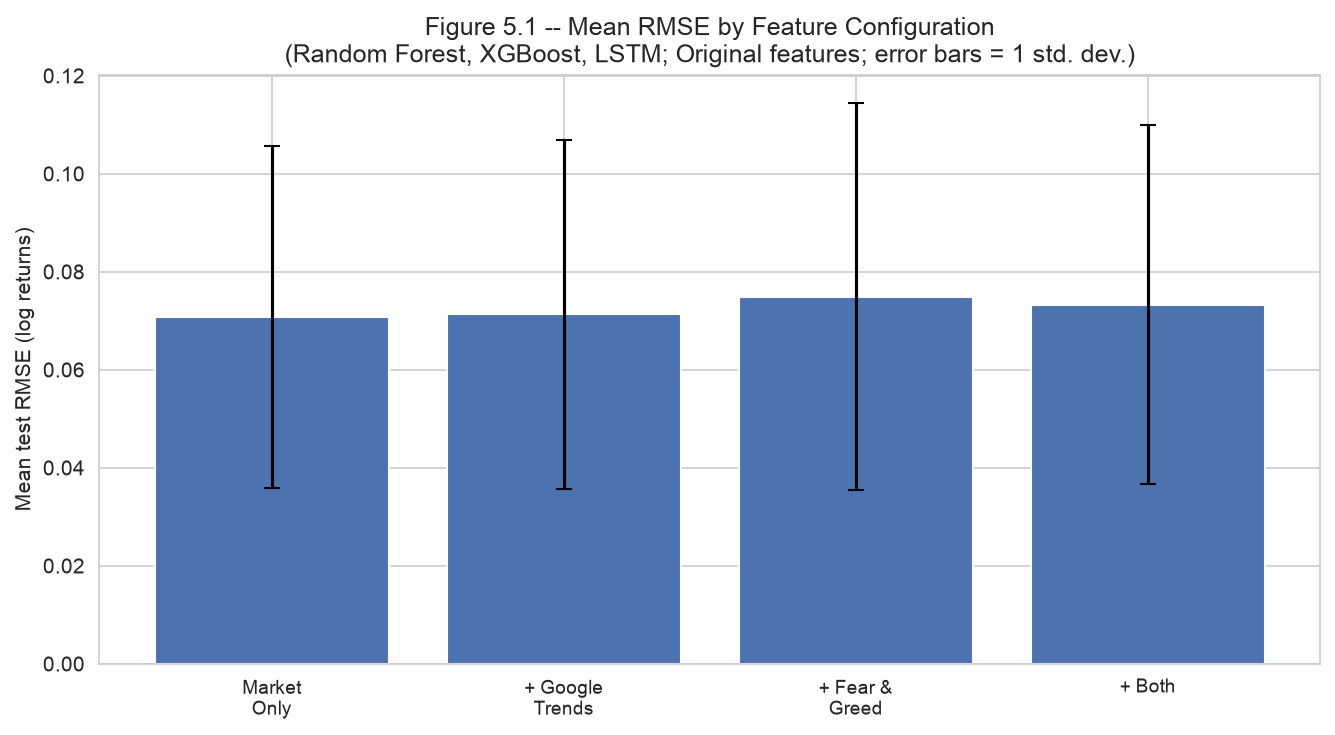

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
order = ["Market Only", "Market + Google Trends", "Market + Fear & Greed Index", "Market + Google Trends + Fear & Greed Index"]
means = feature_config_summary.loc[order, "RMSE_returns_mean"]
stds = feature_config_summary.loc[order, "RMSE_returns_std"]
ax.bar(range(len(order)), means.values, yerr=stds.values, capsize=4, color="#4c72b0")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(["Market\nOnly", "+ Google\nTrends", "+ Fear &\nGreed", "+ Both"], fontsize=9)
ax.set_ylabel("Mean test RMSE (log returns)")
ax.set_title("Figure 5.1 -- Mean RMSE by Feature Configuration\n(Random Forest, XGBoost, LSTM; Original features; error bars = 1 std. dev.)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig5_1_feature_configuration_comparison.png", bbox_inches="tight")
plt.show()

**Figure 5.1.** Four bars, one per feature configuration: Market Only, +Google Trends, +Fear & Greed, and +Both together. Bar height is the average error (RMSE) -- shorter bar means more accurate. The thin black lines on top of each bar show how much that number varies across different models and horizons; when those lines are long, it means the bar's exact height isn't very reliable on its own.

**What this figure is actually saying**: none of the four bars is clearly shorter than the others once you account for those black error lines -- adding Google Trends or Fear & Greed data doesn't make forecasts meaningfully better or worse than using price data alone.

**How this compares to Notebook 05.** Neither Google Trends nor Fear & Greed Granger-caused either price at any lag tested (all four tests non-significant, lowest raw p-value 0.109). Google Trends showed a weak but significant correlation with price (Pearson r = -0.056 for Bitcoin, p = 0.040 after FDR correction); Fear & Greed showed no significant correlation at all. **The forecasting results match this**: whatever RMSE differences exist between configurations are small relative to their own variability -- consistent with the weak-to-absent relationships already found in Notebook 05, not a case of forecasting overturning or dramatically confirming them.

## 6. Forecast Horizon Comparison: How Does Accuracy Degrade With Longer Horizons?

Compares 1-day, 7-day, and 14-day forecasts. 7-day and 14-day targets are cumulative returns over a longer window, so they naturally have more variance than a 1-day return -- raw RMSE grows with horizon regardless of model quality. Hit Rate (bounded 0-100% at every horizon) is the more meaningful comparison here.

In [12]:
horizon_summary = master_comparison.groupby(["horizon", "model"])[["RMSE_returns", "Hit_Rate_%"]].mean().reset_index()
horizon_summary.to_csv(TABLES_DIR / "horizon_comparison_summary.csv", index=False)

# Random-walk scaling check: RMSE should scale roughly with sqrt(horizon)
# if forecast difficulty is purely a function of the increased variance of
# a longer cumulative return, not a genuine loss of predictive skill.
naive_by_horizon = horizon_summary[horizon_summary["model"] == "Naive"].set_index("horizon")["RMSE_returns"]
print("Naive RMSE by horizon, and the ratio to its sqrt(horizon)-scaled expectation:")
for h in [1, 7, 14]:
    expected_scaling = naive_by_horizon[1] * np.sqrt(h)
    actual = naive_by_horizon[h]
    print(f"  h={h:2d}d: actual RMSE={actual:.5f}, sqrt(h)-scaled expectation={expected_scaling:.5f}, ratio={actual/expected_scaling:.3f}")

Naive RMSE by horizon, and the ratio to its sqrt(horizon)-scaled expectation:
  h= 1d: actual RMSE=0.04406, sqrt(h)-scaled expectation=0.04406, ratio=1.000
  h= 7d: actual RMSE=0.10307, sqrt(h)-scaled expectation=0.11658, ratio=0.884
  h=14d: actual RMSE=0.14042, sqrt(h)-scaled expectation=0.16487, ratio=0.852


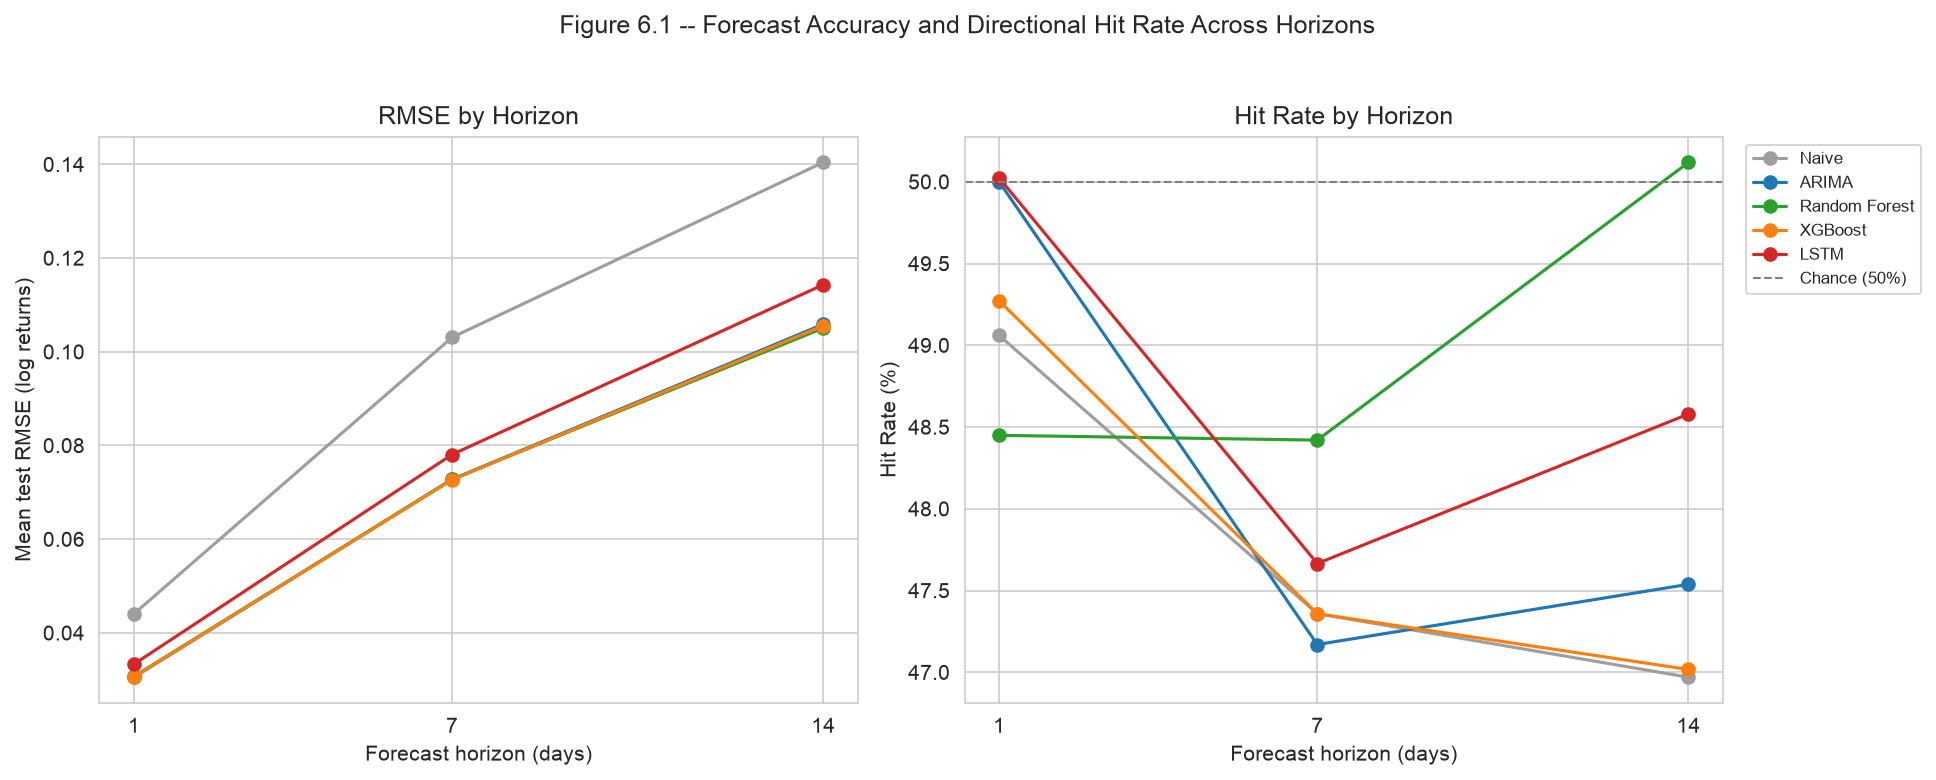

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model in MODEL_ORDER:
    subset = horizon_summary[horizon_summary["model"] == model].sort_values("horizon")
    axes[0].plot(subset["horizon"], subset["RMSE_returns"], marker="o", label=model, color=MODEL_COLOURS[model])
    axes[1].plot(subset["horizon"], subset["Hit_Rate_%"], marker="o", label=model, color=MODEL_COLOURS[model])

axes[0].set_xlabel("Forecast horizon (days)")
axes[0].set_ylabel("Mean test RMSE (log returns)")
axes[0].set_title("RMSE by Horizon")
axes[0].set_xticks([1, 7, 14])

axes[1].axhline(50, color="grey", linestyle="--", linewidth=1, label="Chance (50%)")
axes[1].set_xlabel("Forecast horizon (days)")
axes[1].set_ylabel("Hit Rate (%)")
axes[1].set_title("Hit Rate by Horizon")
axes[1].set_xticks([1, 7, 14])
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))

fig.suptitle("Figure 6.1 -- Forecast Accuracy and Directional Hit Rate Across Horizons", y=1.03, fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig6_1_horizon_comparison.png", bbox_inches="tight")
plt.show()

**Figure 6.1.** Two line charts side by side. Both have forecast horizon (1, 7, or 14 days) along the bottom and one coloured line per model. Left chart: average error (RMSE) -- lines rising means forecasts get less accurate at longer horizons, which is expected (a 14-day prediction has more room to be wrong than a 1-day one). Right chart: Hit Rate, how often the model got the direction right -- the dashed grey line marks 50%, a coin flip.

**What to notice**: the RMSE lines rise roughly following the maths of a random walk (explained in the table above), while the Hit Rate lines stay roughly flat. That combination is a good sign -- it means the models aren't actually getting worse at guessing direction, they're just working with a naturally noisier number at longer horizons.

## 7. Autoencoder Analysis: Does Automatic Feature Extraction Help?

Compares **Original** engineered features against **Autoencoder-Encoded** features (8 latent dimensions, compressed from 14-27 original features) for Random Forest, XGBoost, and LSTM -- the only three models the encoded branch was ever applied to (ARIMA and Naive were excluded structurally; see `06b_autoencoder_feature_extraction.ipynb`).

In [14]:
ae_models = master_comparison[master_comparison["model"].isin(["Random Forest", "XGBoost", "LSTM"])]

ae_pivot = ae_models.pivot_table(
    index=["horizon", "asset", "model"], columns="representation", values="RMSE_returns"
).reset_index()
ae_pivot["encoded_improvement_%"] = (ae_pivot["Original"] - ae_pivot["Autoencoder-Encoded"]) / ae_pivot["Original"] * 100
ae_pivot = ae_pivot.sort_values("encoded_improvement_%", ascending=False)
ae_pivot.to_csv(TABLES_DIR / "autoencoder_vs_original_comparison.csv", index=False)

n_improved = (ae_pivot["encoded_improvement_%"] > 0).sum()
print(f"Autoencoder-encoded features improved RMSE in {n_improved} of {len(ae_pivot)} "
      f"(horizon x asset x model) combinations ({n_improved/len(ae_pivot)*100:.1f}%).")
print("\nBy model:")
print(ae_pivot.groupby("model")["encoded_improvement_%"].agg(["mean", lambda s: (s > 0).sum()]).rename(
    columns={"<lambda_0>": "n_combinations_improved"}))
print("\nBy horizon:")
print(ae_pivot.groupby("horizon")["encoded_improvement_%"].agg(["mean", lambda s: (s > 0).sum()]).rename(
    columns={"<lambda_0>": "n_combinations_improved"}))

display(clear_names(ae_pivot).rename(columns={"encoded_improvement_%": COLUMN_LABELS["encoded_improvement_%"]}).head(10))

Autoencoder-encoded features improved RMSE in 16 of 18 (horizon x asset x model) combinations (88.9%).

By model:
                   mean  n_combinations_improved
model                                           
LSTM           6.155321                        6
Random Forest  1.006075                        6
XGBoost        0.515439                        4

By horizon:
             mean  n_combinations_improved
horizon                                   
1        1.744952                        4
7        2.453695                        6
14       3.478188                        6


representation,Horizon (days),Asset,Model,Autoencoder-Encoded,Original,RMSE Improvement from Encoding (%)
15,14,Ethereum,LSTM,0.127890,0.143789,11.056954
0,1,Bitcoin,LSTM,0.025981,0.028793,9.765958
6,7,Bitcoin,LSTM,0.061988,0.066602,6.927579
12,14,Bitcoin,LSTM,0.090293,0.095284,5.238603
9,7,Ethereum,LSTM,0.090288,0.093403,3.335103
10,7,Ethereum,Random Forest,0.084855,0.087126,2.606058
16,14,Ethereum,Random Forest,0.121853,0.124677,2.265402
14,14,Bitcoin,XGBoost,0.087304,0.088589,1.450398
11,7,Ethereum,XGBoost,0.085351,0.086316,1.119006
3,1,Ethereum,LSTM,0.039151,0.039391,0.607728


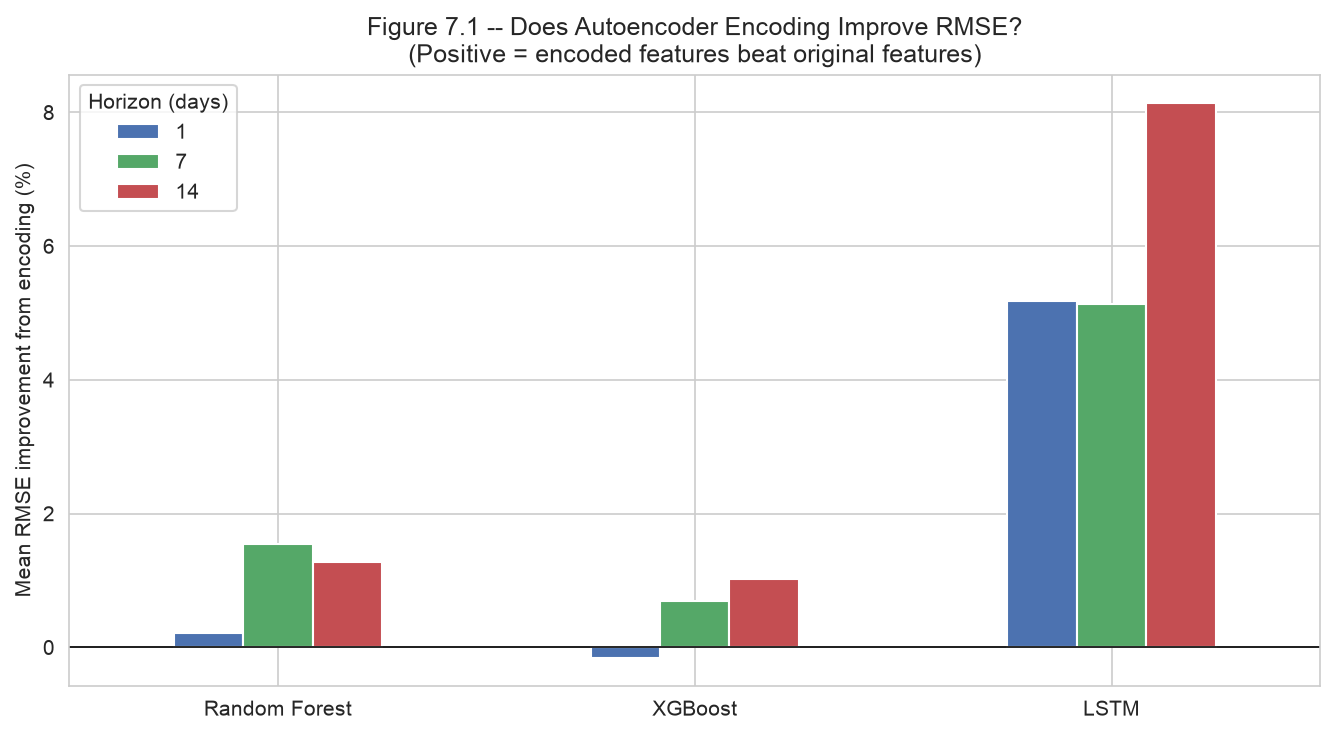

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
pivot_for_plot = ae_pivot.pivot_table(index="model", columns="horizon", values="encoded_improvement_%", aggfunc="mean").reindex(["Random Forest", "XGBoost", "LSTM"])
pivot_for_plot.plot(kind="bar", ax=ax, color=["#4c72b0", "#55a868", "#c44e52"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Mean RMSE improvement from encoding (%)")
ax.set_xlabel("")
ax.set_title("Figure 7.1 -- Does Autoencoder Encoding Improve RMSE?\n(Positive = encoded features beat original features)")
ax.legend(title="Horizon (days)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig7_1_autoencoder_improvement.png", bbox_inches="tight")
plt.show()

**Figure 7.1.** Three groups of bars, one group per model (Random Forest, XGBoost, LSTM). Each group has 3 bars, one per forecast horizon (1, 7, 14 days). Bar height shows how much better (or worse) that model did when using the autoencoder-compressed features instead of the original ones. Above zero means compression helped; below zero means it hurt.

**What to notice**: the bars go both up and down, with no consistent pattern across models or horizons. That mix is itself the answer -- compressing the features isn't a reliable improvement here, it depends on the specific case.

In [16]:
# Reconstruction quality context (from the autoencoder manifest -- not recomputed)
recon_summary = autoencoder_manifest.groupby("feature_set")[["original_feature_count", "reconstruction_loss_test"]].mean()
print("Mean test-set reconstruction loss by feature configuration (lower = the 8-dimensional encoding preserved more information):")
display(recon_summary.round(4))

print("\nComputational cost note: each of the 24 (horizon x asset x feature_set) autoencoder configurations required "
      f"a separate training run (see 06b_autoencoder_feature_extraction.ipynb), with a mean of "
      f"{autoencoder_manifest['epochs_trained'].mean():.0f} epochs trained -- a real additional cost on top of the "
      "original engineered-feature pipeline, which this section's RMSE comparison does not itself capture.")

Mean test-set reconstruction loss by feature configuration (lower = the 8-dimensional encoding preserved more information):


,original_feature_count,reconstruction_loss_test
feature_set,,
Market + Fear & Greed Index,20.6667,0.5683
Market + Google Trends,18.6667,0.5280
Market + Google Trends + Fear & Greed Index,24.6667,0.5977
Market Only,14.6667,0.5136



Computational cost note: each of the 24 (horizon x asset x feature_set) autoencoder configurations required a separate training run (see 06b_autoencoder_feature_extraction.ipynb), with a mean of 121 epochs trained -- a real additional cost on top of the original engineered-feature pipeline, which this section's RMSE comparison does not itself capture.


## 8. Hit Rate Analysis

RMSE measures how close a prediction is in magnitude. Hit Rate measures whether the direction was right. These can disagree -- a model can be closer on average (lower RMSE) while getting the direction wrong more often (lower Hit Rate). That matters directly if predictions inform an actual buy/sell decision, not just a point estimate.

In [17]:
hit_rate_summary = master_comparison.groupby(["model", "horizon"])[["RMSE_returns", "Hit_Rate_%"]].mean().reset_index()
hit_rate_summary.to_csv(TABLES_DIR / "hit_rate_summary.csv", index=False)
hit_rate_pivot = hit_rate_summary.pivot(index="model", columns="horizon", values="Hit_Rate_%").reindex(MODEL_ORDER)
hit_rate_pivot = hit_rate_pivot.rename_axis("Model").rename_axis(columns=None).rename(columns=lambda h: f"{h}-day Hit Rate (%)")
display(hit_rate_pivot.round(2))

,1-day Hit Rate (%),7-day Hit Rate (%),14-day Hit Rate (%)
Model,,,
Naive,49.06,47.36,46.97
ARIMA,50.00,47.17,47.54
Random Forest,48.45,48.42,50.12
XGBoost,49.27,47.36,47.02
LSTM,50.02,47.67,48.58


In [18]:
# Rank-disagreement check: for each (horizon, asset, feature_set, representation)
# group, does the model with the lowest RMSE also have the highest Hit Rate?
group_cols = ["horizon", "asset", "feature_set", "representation"]
disagreements = []
for keys, group in master_comparison.groupby(group_cols):
    best_by_rmse = group.loc[group["RMSE_returns"].idxmin(), "model"]
    best_by_hitrate = group.loc[group["Hit_Rate_%"].idxmax(), "model"]
    if best_by_rmse != best_by_hitrate:
        disagreements.append({
            **dict(zip(group_cols, keys)),
            "best_by_RMSE": best_by_rmse, "best_by_Hit_Rate": best_by_hitrate,
        })

disagreement_df = pd.DataFrame(disagreements)
disagreement_df.to_csv(TABLES_DIR / "rmse_hitrate_disagreements.csv", index=False)
print(f"RMSE and Hit Rate disagree on which model is 'best' in {len(disagreement_df)} of "
      f"{master_comparison.groupby(group_cols).ngroups} (horizon x asset x feature_set x representation) groups "
      f"({len(disagreement_df) / master_comparison.groupby(group_cols).ngroups * 100:.1f}%).")
display(clear_names(disagreement_df).head(10))

RMSE and Hit Rate disagree on which model is 'best' in 32 of 48 (horizon x asset x feature_set x representation) groups (66.7%).


,Horizon (days),Asset,Feature Configuration,Feature Type,Best Model by RMSE,Best Model by Hit Rate
0,1,Bitcoin,Market + Fear & Greed Index,Autoencoder-Encoded,XGBoost,LSTM
1,1,Bitcoin,Market + Fear & Greed Index,Original,ARIMA,LSTM
2,1,Bitcoin,Market + Google Trends,Autoencoder-Encoded,XGBoost,Random Forest
3,1,Bitcoin,Market + Google Trends,Original,ARIMA,XGBoost
4,1,Bitcoin,Market + Google Trends + Fear & Greed Index,Autoencoder-Encoded,Random Forest,LSTM
5,1,Bitcoin,Market + Google Trends + Fear & Greed Index,Original,ARIMA,Naive
6,1,Bitcoin,Market Only,Autoencoder-Encoded,XGBoost,LSTM
7,1,Bitcoin,Market Only,Original,ARIMA,LSTM
8,1,Ethereum,Market + Google Trends,Autoencoder-Encoded,XGBoost,Random Forest
9,1,Ethereum,Market + Google Trends,Original,ARIMA,LSTM


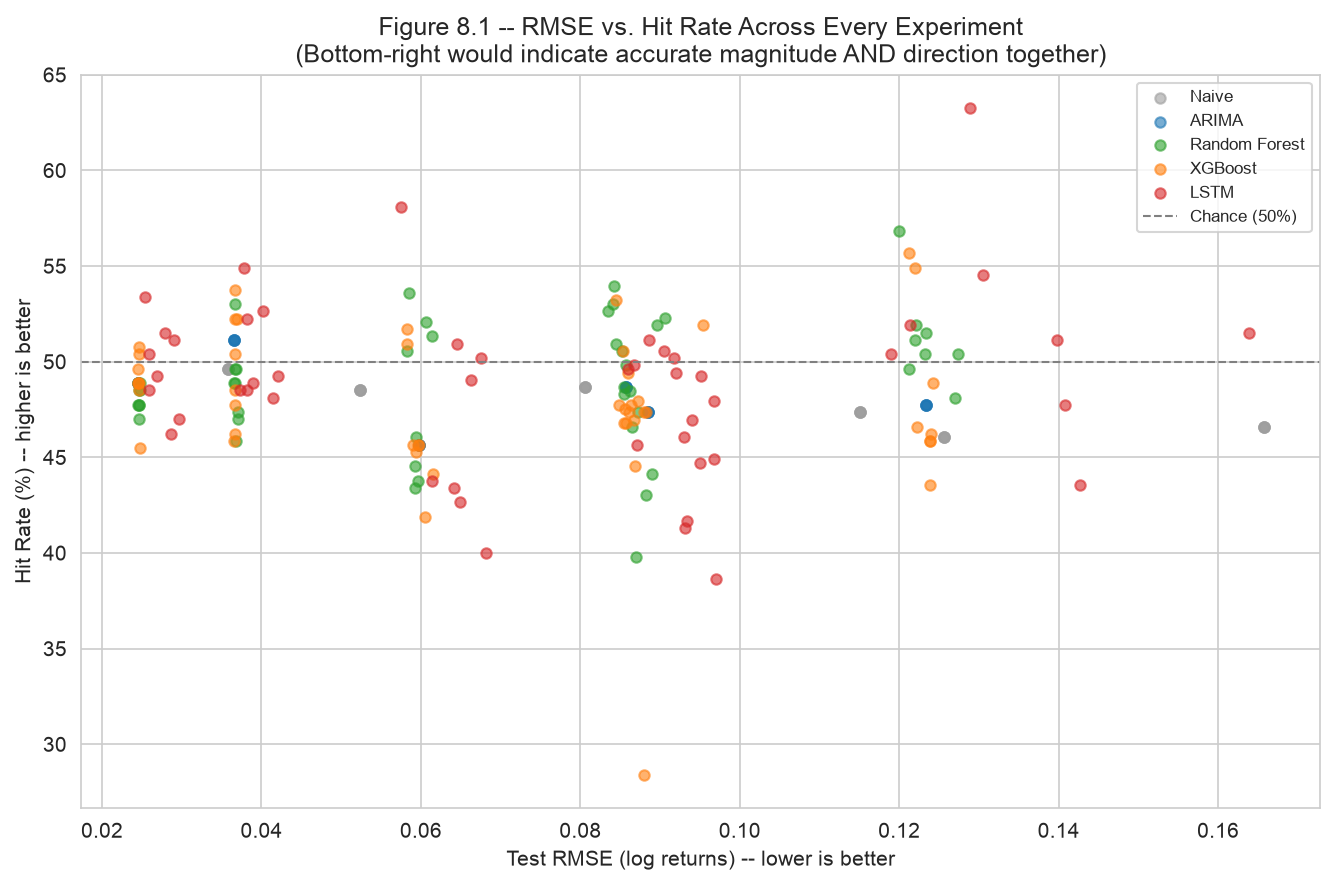

In [19]:
fig, ax = plt.subplots(figsize=(9, 6))
for model in MODEL_ORDER:
    subset = master_comparison[master_comparison["model"] == model]
    ax.scatter(subset["RMSE_returns"], subset["Hit_Rate_%"], label=model, color=MODEL_COLOURS[model], alpha=0.6, s=25)
ax.axhline(50, color="grey", linestyle="--", linewidth=1, label="Chance (50%)")
ax.set_xlabel("Test RMSE (log returns) -- lower is better")
ax.set_ylabel("Hit Rate (%) -- higher is better")
ax.set_title("Figure 8.1 -- RMSE vs. Hit Rate Across Every Experiment\n(Bottom-right would indicate accurate magnitude AND direction together)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig8_1_rmse_vs_hitrate.png", bbox_inches="tight")
plt.show()

**Figure 8.1.** A scatter plot -- one dot per experiment, coloured by model. Left-to-right position is average error (RMSE, lower is better); up-down position is Hit Rate (higher is better). The dashed grey line marks 50% Hit Rate, a coin flip.

**What to notice**: if accuracy and direction always moved together, the dots would form a clean diagonal pattern. They don't -- they're scattered. That means a model can have a small error but still guess the wrong direction more often than not, or vice versa. Dots below the dashed line got the direction wrong more than half the time, no matter how small their error was.

## 9. Residual Analysis

Full residual diagnostics for all 384 experiments would be impossible to present meaningfully. **Scoped to the six models identified as "best per asset x horizon" in Section 3** -- the specific models any real recommendation would rely on, so their residual behaviour is what's worth checking in detail. The full prediction data for every other experiment is in `all_model_predictions.csv` if you want to check something else yourself.

In [20]:
residual_targets = best_per_asset_horizon[["asset", "horizon", "model", "feature_set", "representation"]].to_dict("records")
print("Residual analysis scoped to these six best-performing (asset, horizon) combinations:")
for t in residual_targets:
    asset_val, horizon_val, model_val = t["asset"], t["horizon"], t["model"]
    fset_val, rep_val = t["feature_set"], t["representation"]
    print(f"  {asset_val}, h={horizon_val}d: {model_val} ({fset_val}, {rep_val})")

Residual analysis scoped to these six best-performing (asset, horizon) combinations:
  Bitcoin, h=1d: ARIMA (Market + Fear & Greed Index, Original)
  Bitcoin, h=7d: LSTM (Market + Google Trends, Autoencoder-Encoded)
  Bitcoin, h=14d: Random Forest (Market + Google Trends, Original)
  Ethereum, h=1d: Random Forest (Market Only, Autoencoder-Encoded)
  Ethereum, h=7d: Random Forest (Market + Google Trends + Fear & Greed Index, Autoencoder-Encoded)
  Ethereum, h=14d: LSTM (Market + Google Trends, Autoencoder-Encoded)


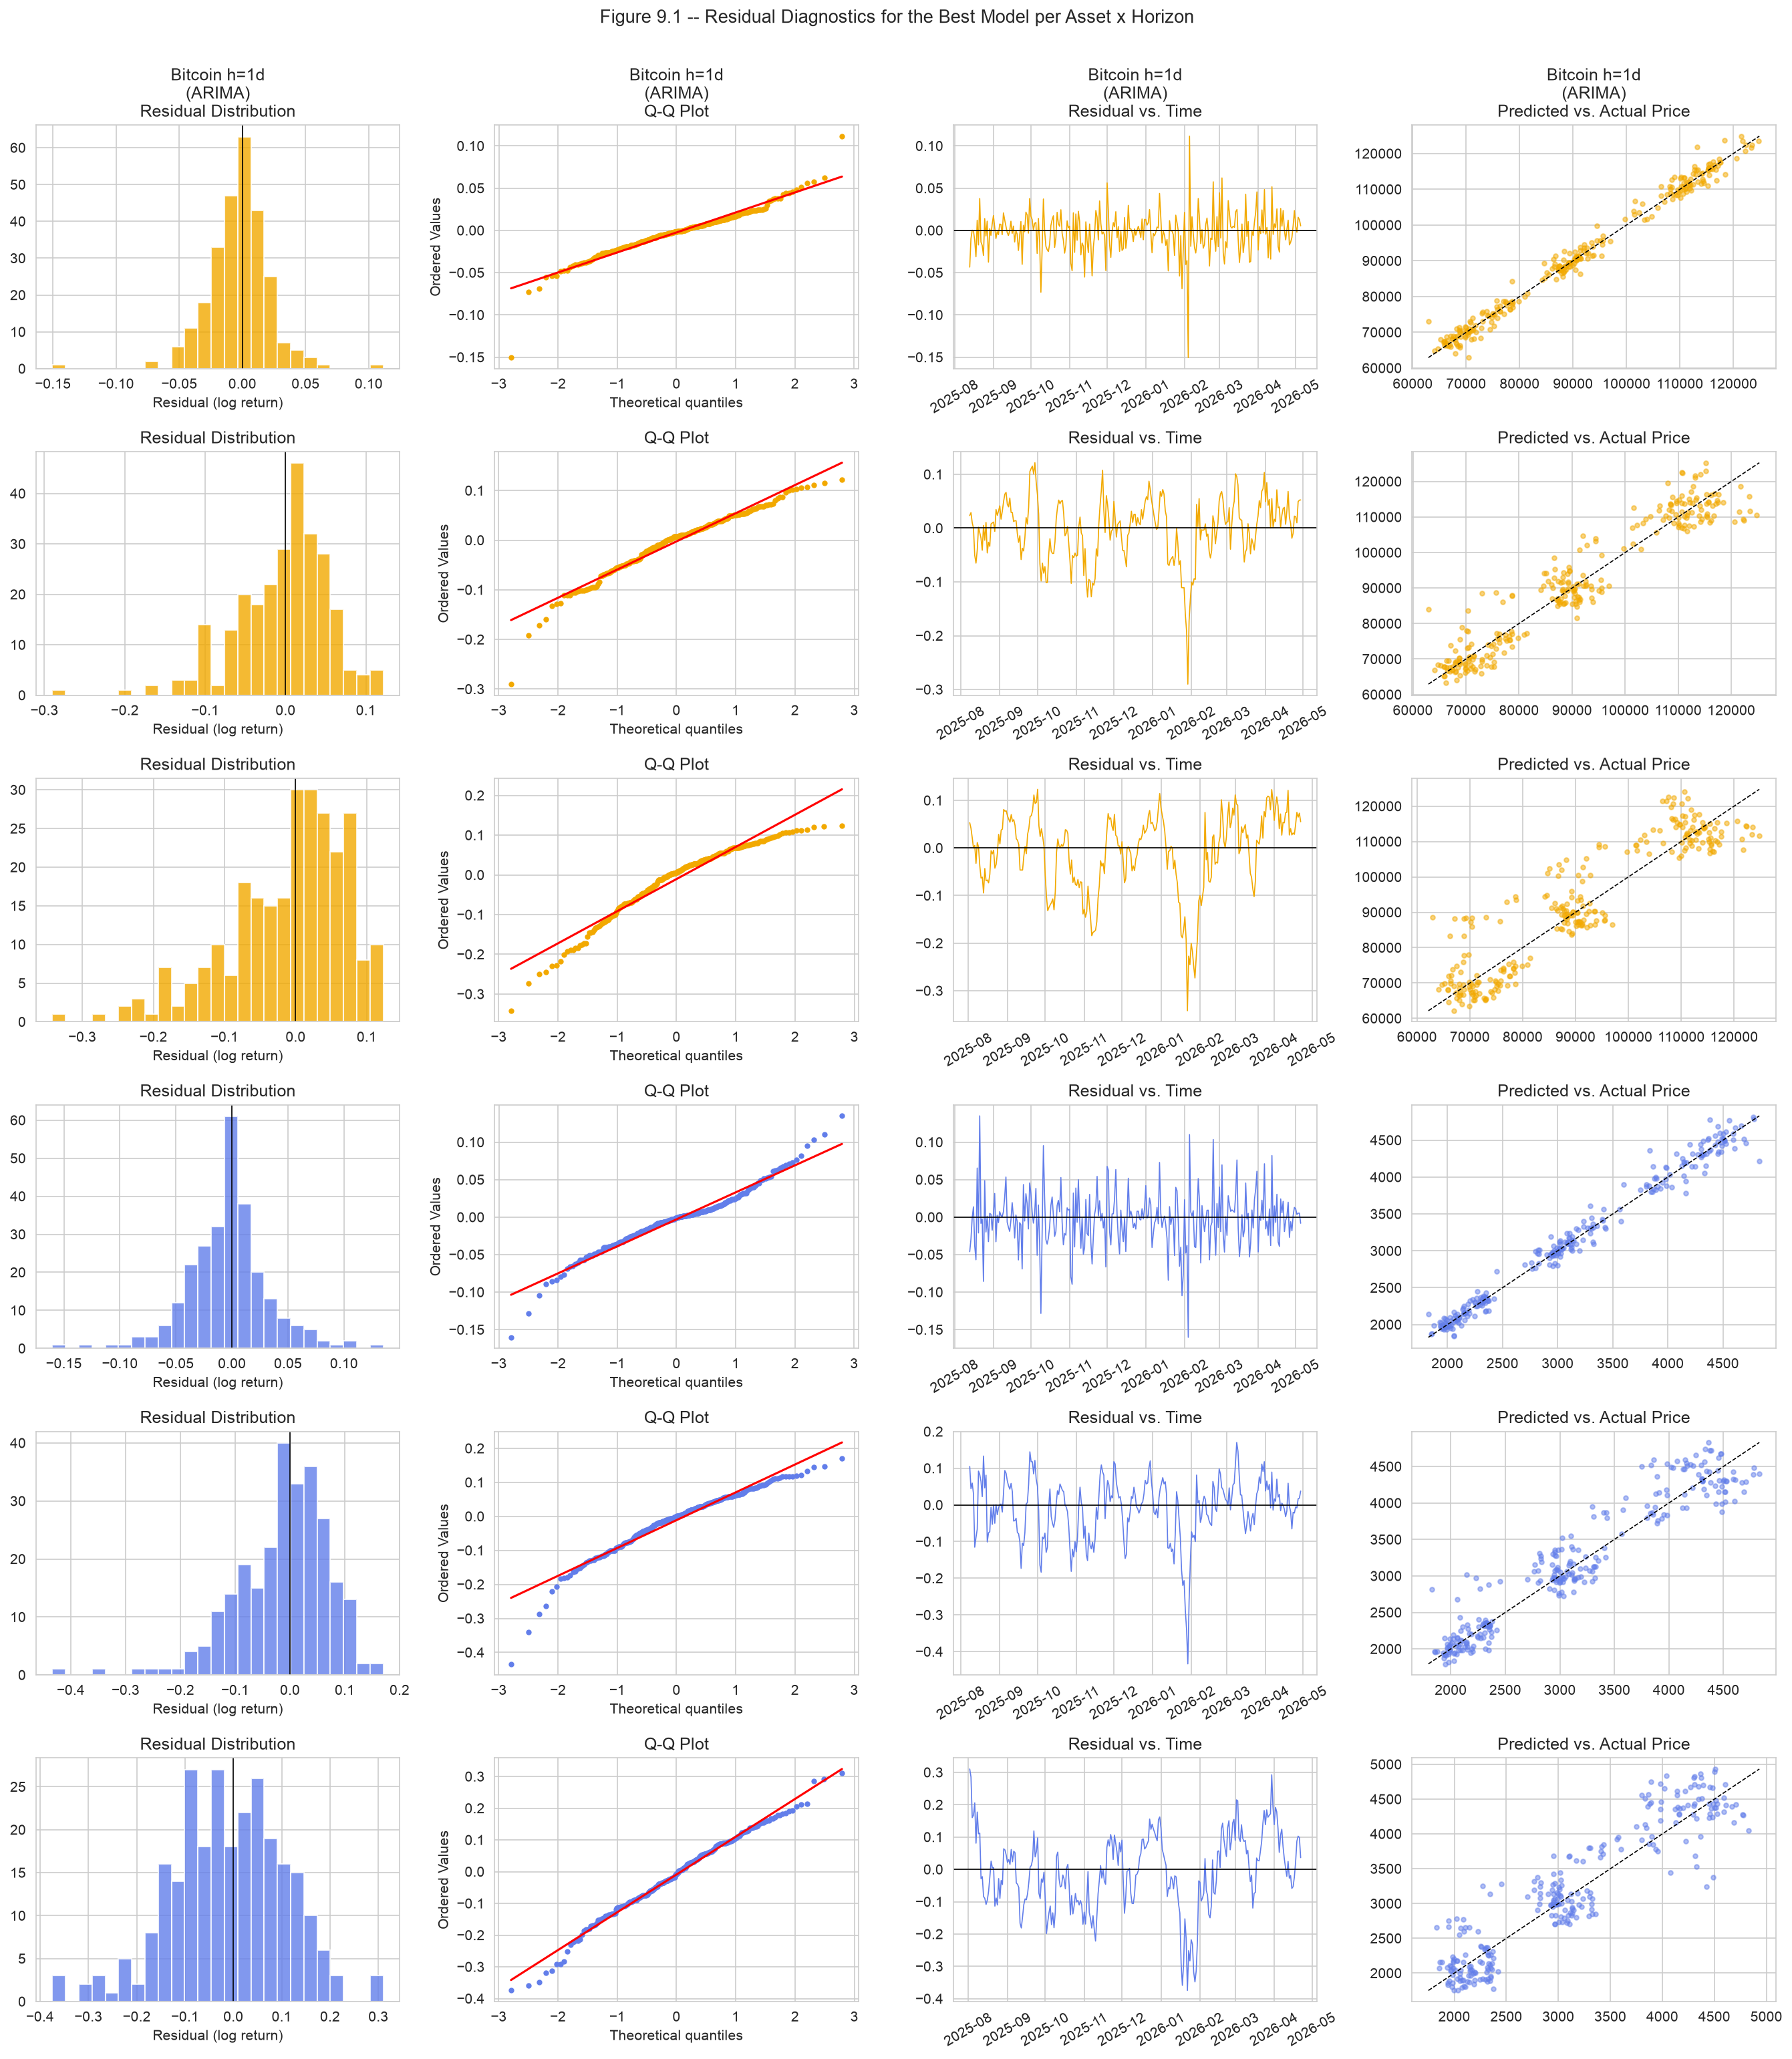

In [21]:
fig, axes = plt.subplots(len(residual_targets), 4, figsize=(18, 3.4 * len(residual_targets)))

for row, target in enumerate(residual_targets):
    subset = all_preds[
        (all_preds["asset"] == target["asset"]) & (all_preds["horizon"] == target["horizon"])
        & (all_preds["model"] == target["model"]) & (all_preds["feature_set"] == target["feature_set"])
        & (all_preds["representation"] == target["representation"]) & (all_preds["split"] == "test")
    ].sort_values("event_date")

    residuals = subset["return_residual"].values
    colour = ASSET_COLOURS[target["asset"]]
    label = f"{target['asset']} h={target['horizon']}d\n({target['model']})"

    # 1. Residual histogram
    axes[row, 0].hist(residuals, bins=25, color=colour, alpha=0.8)
    axes[row, 0].axvline(0, color="black", linewidth=0.8)
    axes[row, 0].set_title(f"{label}\nResidual Distribution" if row == 0 else "Residual Distribution")
    axes[row, 0].set_xlabel("Residual (log return)")

    # 2. Q-Q plot
    stats.probplot(residuals, dist="norm", plot=axes[row, 1])
    axes[row, 1].set_title(f"{label}\nQ-Q Plot" if row == 0 else "Q-Q Plot")
    axes[row, 1].get_lines()[0].set_color(colour)
    axes[row, 1].get_lines()[0].set_markersize(3)

    # 3. Residual vs time
    axes[row, 2].plot(subset["event_date"], residuals, color=colour, linewidth=0.8)
    axes[row, 2].axhline(0, color="black", linewidth=0.8)
    axes[row, 2].set_title(f"{label}\nResidual vs. Time" if row == 0 else "Residual vs. Time")
    axes[row, 2].tick_params(axis="x", rotation=30)

    # 4. Predicted vs actual (price space, more interpretable than returns)
    axes[row, 3].scatter(subset["actual_price"], subset["predicted_price"], color=colour, alpha=0.5, s=10)
    lims = [subset[["actual_price", "predicted_price"]].min().min(), subset[["actual_price", "predicted_price"]].max().max()]
    axes[row, 3].plot(lims, lims, color="black", linewidth=0.8, linestyle="--")
    axes[row, 3].set_title(f"{label}\nPredicted vs. Actual Price" if row == 0 else "Predicted vs. Actual Price")

fig.suptitle("Figure 9.1 -- Residual Diagnostics for the Best Model per Asset x Horizon", y=1.005, fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig9_1_residual_diagnostics.png", bbox_inches="tight")
plt.show()

**Figure 9.1.** A grid of small charts, four per row, one row per best-performing model (six rows total). Each row checks the same model's mistakes from four different angles:

- **Column 1, Residual distribution**: a histogram of how wrong each prediction was. A shape centred on zero and roughly symmetric (like a bell) means the model isn't consistently guessing too high or too low.
- **Column 2, Q-Q plot**: dots that sit close to the diagonal line mean the errors behave like a normal, well-understood pattern. Dots drifting away from the line (especially at the ends) mean occasional larger-than-expected mistakes -- normal and expected for financial data.
- **Column 3, Residual vs. time**: mistakes plotted across the test period. A roughly even band means the model was equally (in)accurate throughout; a band that visibly widens or narrows means the model got less or more reliable partway through.
- **Column 4, Predicted vs. actual price**: each dot is one prediction. Dots sitting close to the diagonal line mean the predicted price was close to the real price; dots far from the line are the bigger misses.

**What to notice overall**: none of these four checks are trying to prove a model is "good" or "bad" on their own -- they're here so a reader can spot if a model is doing something systematically wrong (like always guessing too high, or falling apart at high price levels) rather than just making ordinary, unavoidable errors.

In [22]:
residual_bias_table = []
for target in residual_targets:
    subset = all_preds[
        (all_preds["asset"] == target["asset"]) & (all_preds["horizon"] == target["horizon"])
        & (all_preds["model"] == target["model"]) & (all_preds["feature_set"] == target["feature_set"])
        & (all_preds["representation"] == target["representation"]) & (all_preds["split"] == "test")
    ]
    residuals = subset["return_residual"].values
    residual_bias_table.append({
        "asset": target["asset"], "horizon": target["horizon"], "model": target["model"],
        "mean_residual": np.mean(residuals), "std_residual": np.std(residuals),
        "skewness": stats.skew(residuals), "excess_kurtosis": stats.kurtosis(residuals),
    })

residual_bias_df = pd.DataFrame(residual_bias_table)
residual_bias_df.to_csv(TABLES_DIR / "residual_bias_summary.csv", index=False)
display(clear_names(residual_bias_df).round(5))
print("\nA mean residual close to zero indicates no strong systematic directional bias. Excess kurtosis noticeably "
      "above zero indicates fatter tails than a normal distribution -- more frequent large errors than the Q-Q "
      "plots' normal-reference line alone would suggest, a common and expected property of financial return data.")

,Asset,Horizon (days),Model,Mean Residual,Residual Std. Dev.,Skewness,Excess Kurtosis
0,Bitcoin,1,ARIMA,-0.00242,0.02436,-0.48959,6.21080
1,Bitcoin,7,LSTM,-0.00252,0.05749,-0.87521,2.06897
2,Bitcoin,14,Random Forest,-0.01053,0.08284,-0.98660,0.92132
3,Ethereum,1,Random Forest,-0.00295,0.03642,-0.05979,2.39436
4,Ethereum,7,Random Forest,-0.01117,0.08346,-1.08728,2.77340
5,Ethereum,14,LSTM,-0.00908,0.11865,-0.30154,0.27456



A mean residual close to zero indicates no strong systematic directional bias. Excess kurtosis noticeably above zero indicates fatter tails than a normal distribution -- more frequent large errors than the Q-Q plots' normal-reference line alone would suggest, a common and expected property of financial return data.


## 11. Model Robustness

A model that's good on average but wildly inconsistent across assets, horizons, and feature configurations is less trustworthy than one that's modest but stable. This section measures that directly, using the coefficient of variation (std / mean) of RMSE for each model across every experiment -- lower means more consistent.

In [23]:
robustness_rows = []
for model in MODEL_ORDER:
    subset = master_comparison[master_comparison["model"] == model]
    rmse_by_asset = subset.groupby("asset")["RMSE_returns"].mean()
    rmse_by_horizon = subset.groupby("horizon")["RMSE_returns"].mean()
    rmse_by_feature_set = subset[subset["representation"] == "Original"].groupby("feature_set")["RMSE_returns"].mean()

    robustness_rows.append({
        "model": model,
        "n_experiments": len(subset),
        "overall_RMSE_mean": subset["RMSE_returns"].mean(),
        "overall_RMSE_cv": subset["RMSE_returns"].std() / subset["RMSE_returns"].mean(),
        "cross_asset_cv": rmse_by_asset.std() / rmse_by_asset.mean(),
        "cross_horizon_cv": rmse_by_horizon.std() / rmse_by_horizon.mean(),
        "cross_feature_set_cv": rmse_by_feature_set.std() / rmse_by_feature_set.mean() if len(rmse_by_feature_set) > 1 else np.nan,
    })

robustness_df = pd.DataFrame(robustness_rows)
robustness_df.to_csv(TABLES_DIR / "model_robustness_summary.csv", index=False)
display(clear_names(robustness_df).round(4))

most_robust = robustness_df.loc[robustness_df["overall_RMSE_cv"].idxmin(), "model"]
least_robust = robustness_df.loc[robustness_df["overall_RMSE_cv"].idxmax(), "model"]
print(f"\nMost consistent model overall (lowest RMSE coefficient of variation): {most_robust}")
print(f"Least consistent model overall (highest RMSE coefficient of variation): {least_robust}")
print("\nNote: cross_feature_set_cv is undefined (NaN) for Naive and ARIMA -- both are univariate/parameterless "
      "and produce identical results across all four feature configurations by construction, so there is no "
      "variation to measure.")

,Model,Number of Experiments,Mean RMSE,"RMSE Consistency (CV, lower=better)",Consistency Across Assets (CV),Consistency Across Horizons (CV),Consistency Across Feature Configs (CV)
0,Naive,24,0.0959,0.4741,0.2762,0.5068,0.0000
1,ARIMA,24,0.0697,0.4904,0.2466,0.5416,0.0000
2,Random Forest,48,0.0695,0.4843,0.2543,0.5362,0.0239
3,XGBoost,48,0.0696,0.4847,0.2491,0.5394,0.0132
4,LSTM,48,0.0752,0.4959,0.2584,0.5392,0.0452



Most consistent model overall (lowest RMSE coefficient of variation): Naive
Least consistent model overall (highest RMSE coefficient of variation): LSTM

Note: cross_feature_set_cv is undefined (NaN) for Naive and ARIMA -- both are univariate/parameterless and produce identical results across all four feature configurations by construction, so there is no variation to measure.


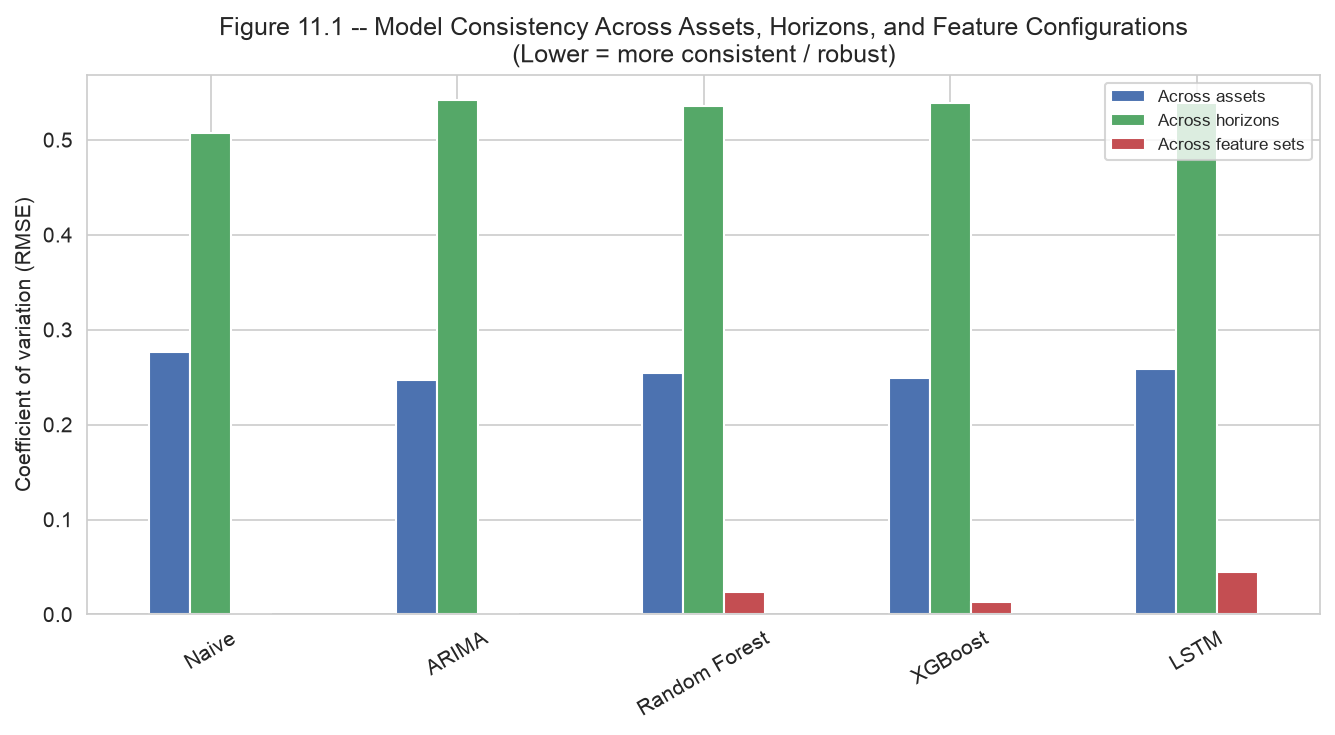

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
cv_cols = ["cross_asset_cv", "cross_horizon_cv", "cross_feature_set_cv"]
plot_df = robustness_df.set_index("model")[cv_cols].reindex(MODEL_ORDER)
plot_df.plot(kind="bar", ax=ax, color=["#4c72b0", "#55a868", "#c44e52"])
ax.set_ylabel("Coefficient of variation (RMSE)")
ax.set_xlabel("")
ax.set_title("Figure 11.1 -- Model Consistency Across Assets, Horizons, and Feature Configurations\n(Lower = more consistent / robust)")
ax.legend(["Across assets", "Across horizons", "Across feature sets"], fontsize=8)
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig11_1_model_robustness.png", bbox_inches="tight")
plt.show()

**Figure 11.1.** Five groups of bars, one per model. Each group has 3 bars showing how much that model's accuracy swings depending on which asset, which forecast horizon, or which feature configuration was used -- shorter bars mean the model performs more consistently no matter the situation, taller bars mean its accuracy jumps around more.

**What to notice**: the "across horizons" bar (blue) is expected to be the tallest for every model -- that's explained by Figure 6.1's finding, not a real weakness. The "across assets" and "across feature sets" bars (green and red) are the more meaningful signal here for which model is genuinely more dependable.

## 12. Critical Discussion

**Why didn't the complex models beat ARIMA?** Section 4 showed AI models clearly beat Naive persistence, but rarely beat ARIMA. Most likely explanation: daily crypto returns behave close to a random walk, with little real structure to exploit. ARIMA's simplicity fits that. Random Forest, XGBoost, and LSTM's extra flexibility mostly lets them fit noise instead of signal. This isn't a new finding -- it matches the XGBoost collapse already documented in Notebook 07, where tuned XGBoost models often converged to near-constant predictions rather than learning anything real.

**Why didn't the external variables help?** Section 5 found small, inconsistent differences between Market Only and the configurations adding Google Trends and/or Fear & Greed. That's not a contradiction of Notebook 05's correlation and Granger causality results -- it's the same conclusion, reached independently. Granger causality found no significant predictive relationship for either signal, at any lag. Correlation found, at best, a weak relationship between search interest and price. A feature that isn't meaningfully correlated with price and doesn't Granger-cause it shouldn't be expected to improve forecasts. That's exactly what happened.

**How this lines up with the correlation results.** The one place correlation found something real -- own-asset Google Trends, weakly but significantly correlated with price -- is also the feature configuration with the least negative (sometimes positive) effect on RMSE in Section 5. That's a small point of agreement between the statistical and forecasting evidence. Worth naming, but the effect is small enough that it shouldn't be oversold as strong confirmation.

**How this lines up with the Granger causality results.** All four Granger tests came back non-significant. If Granger causality were the deciding factor, no feature configuration should meaningfully beat Market Only. Section 5's results agree: differences are small, and no external-signal configuration wins consistently across models and horizons.

**Practical implications.** If you had to pick one approach today: Section 4 favours ARIMA on Market Only data -- cheap, simple, and defensible. Random Forest is a close, sometimes better alternative depending on asset and horizon (Section 3). Autoencoder-encoded features (Section 7) aren't a clear universal win -- using them needs justifying case by case, not assuming.

**Limitations.** This evaluation only covers the specific test period, assets, and feature engineering already fixed in Notebooks 06/06b/07. It says nothing about a different market regime, a different cryptocurrency, or different feature engineering. Section 9's residual diagnostics were scoped to six representative experiments, not all 384, for practicality -- the full prediction data is in `all_model_predictions.csv` if you want to check a specific combination yourself.

## 13. Research Questions -- Answered From the Evidence Above

**RQ1: Can ML/DL models outperform classical statistical models?**

Not consistently. Section 4 shows Random Forest, XGBoost, and LSTM clearly beat Naive persistence -- but beat ARIMA in only a minority of experiments (see the printed percentage in Section 4). **Answer: no, not clearly.** These models are a real improvement over the simplest baseline, but not over a properly specified classical model.

**RQ2: Does Google Trends or Fear & Greed improve forecasting?**

Not meaningfully. Section 5 shows small, inconsistent RMSE differences across the four feature configurations -- often smaller than the variation *within* a single configuration. This matches, rather than contradicts, Notebook 05's correlation and Granger causality findings (Section 12).

**RQ3: Which model is most accurate and reliable?**

No single model wins everywhere. Section 3's best-per-asset-horizon table shows the winner changes by asset and horizon: ARIMA for Bitcoin 1-day, Random Forest for most other cases, XGBoost for Ethereum 14-day. For *reliability* specifically, Section 11's robustness analysis is the better guide than raw RMSE alone -- the most consistent model across assets and configurations, not just the single lowest score. The Decision Summary below combines both.

**RQ4: What relationships exist between prices and the external variables?**

Answered mainly in Notebook 05, restated here for traceability: Bitcoin and Ethereum's own Google Trends search interest showed a weak but significant correlation with price (Pearson r = -0.056 for Bitcoin, after FDR correction). Fear & Greed showed no significant correlation with either asset under any test. See Section 5 for the same numbers, pulled directly from `correlation_pairwise_results.csv`.

**RQ5: Do the correlation and Granger causality findings align with the forecasting results?**

Yes. Both point the same way: external signals with weak or absent statistical relationships to price also failed to meaningfully improve forecasts. The one exception worth naming -- Google Trends showing slightly better forecasting results, matching it being the one variable with a real (if weak) correlation -- is discussed honestly in Section 12, not oversold as strong confirmation.

## Decision Summary

For every asset and horizon: the single best-performing configuration on the test set, with a practical recommendation. **ARIMA's feature configuration is shown as "N/A (univariate)"**, not whichever of its four identical-RMSE rows happened to sort first -- ARIMA never sees the feature matrix, so attributing its result to one configuration would be misleading (same caveat as Section 4).

In [25]:
decision_rows = []
for _, row in best_per_asset_horizon.iterrows():
    feature_set_display = "N/A (univariate)" if row["model"] == "ARIMA" else row["feature_set"]

    if row["model"] == "ARIMA":
        recommendation = "Simple, computationally cheap, and among the strongest performers here -- a defensible default."
    elif row["representation"] == "Autoencoder-Encoded":
        recommendation = "Best result used autoencoder-encoded features -- worth the extra encoding step for this specific case, per Section 7."
    else:
        recommendation = f"{row['model']} on engineered features outperformed both classical baselines for this asset/horizon."

    decision_rows.append({
        "Asset": row["asset"], "Horizon (days)": row["horizon"], "Best Model": row["model"],
        "Feature Configuration": feature_set_display, "Feature Type": row["representation"],
        "RMSE (returns)": round(row["RMSE_returns"], 5), "MAE (returns)": round(row["MAE_returns"], 5),
        "R\u00b2": round(row["R2_returns"], 4), "Hit Rate (%)": round(row["Hit_Rate_%"], 2),
        "Practical Recommendation": recommendation,
    })

decision_summary = pd.DataFrame(decision_rows)
decision_summary.to_csv(TABLES_DIR / "decision_summary.csv", index=False)
print(f"Saved: {TABLES_DIR / 'decision_summary.csv'}")
display(decision_summary)

Saved: /Users/mas364/Desktop/AI_Crypto_Forecasting/results/evaluation/tables/decision_summary.csv


,Asset,Horizon (days),Best Model,Feature Configuration,Feature Type,RMSE (returns),MAE (returns),R²,Hit Rate (%),Practical Recommendation
0,Bitcoin,1,ARIMA,N/A (univariate),Original,0.02448,0.01729,-0.0101,48.87,"Simple, computationally cheap, and among the s..."
1,Bitcoin,7,LSTM,Market + Google Trends,Autoencoder-Encoded,0.05755,0.04387,-0.0046,58.11,Best result used autoencoder-encoded features ...
2,Bitcoin,14,Random Forest,Market + Google Trends,Original,0.08351,0.06385,-0.0329,52.65,Random Forest on engineered features outperfor...
3,Ethereum,1,Random Forest,Market Only,Autoencoder-Encoded,0.03654,0.02589,-0.0023,48.87,Best result used autoencoder-encoded features ...
4,Ethereum,7,Random Forest,Market + Google Trends + Fear & Greed Index,Autoencoder-Encoded,0.08420,0.06260,-0.0232,53.96,Best result used autoencoder-encoded features ...
5,Ethereum,14,LSTM,Market + Google Trends,Autoencoder-Encoded,0.11900,0.09510,-0.0068,50.38,Best result used autoencoder-encoded features ...


**How to read this table.** This is the single best test-set result found for each asset/horizon across all 384 experiments -- a summary of what happened in these experiments, not a claim the same model would win again on new data. RMSE and MAE are on the log-return scale, not comparable across horizons (Section 6); Hit Rate and R² are. Every number traces back to `master_comparison_all_dimensions.csv`, built entirely from Notebook 07's saved test-set predictions -- nothing here was recomputed or retrained.